# Dogs vs Cats — Data Preparation and Initial CNN Training

Stages 4 and 5: content-disjoint splits, memory-bounded 200 × 200 RGB loading, normalization, training-only augmentation, and a short initial CNN training run. The test set is reserved for final evaluation.


In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Image as DisplayImage, display
from data_pipeline import make_dataset, make_augmentation
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)


## Reproducible splits and leakage checks

Seed 42; approximately 70% training, 15% validation, and 15% test. Files with identical SHA-256 content remain in the same split. This can make split sizes differ slightly from exact percentages. Raw photos are referenced by a CSV manifest instead of being copied.


In [2]:
splits = json.loads((ROOT / 'reports' / 'split_summary.json').read_text())
for split, details in splits['splits'].items():
    print(split, details)
print('Exact duplicate photos beyond unique content:', splits['duplicate_images'])
print('Path overlap:', splits['path_overlap'])
print('Content-hash overlap:', splits['content_hash_overlap'])
assert splits['path_overlap'] == splits['content_hash_overlap'] == 0


train {'count': 17498, 'class_counts': {'cat': 8750, 'dog': 8748}}
validation {'count': 3748, 'class_counts': {'cat': 1874, 'dog': 1874}}
test {'count': 3754, 'class_counts': {'cat': 1876, 'dog': 1878}}
Exact duplicate photos beyond unique content: 6
Path overlap: 0
Content-hash overlap: 0


## Batched preprocessing and training-only augmentation

`tf.data` reads and decodes photos on demand, resizes them to 200 × 200, and scales pixel values to [0, 1]. It buffers paths and a small number of batches rather than the complete decoded dataset. Augmentation is inside the model and is enabled only during training.


In [3]:
images, labels = next(iter(make_dataset('train', batch_size=4, shuffle=False)))
augmentation = make_augmentation()
np.testing.assert_array_equal(augmentation(images, training=False).numpy(), images.numpy())
augmented = augmentation(images, training=True)
print('Batch shape:', images.shape, 'dtype:', images.dtype)
print('Pixel range:', float(tf.reduce_min(images)), float(tf.reduce_max(images)))
print('Labels:', labels.numpy(), '(0=cat, 1=dog)')
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index in range(4):
    axes[0, index].imshow(images[index]); axes[0, index].set_title('Normalized original')
    axes[1, index].imshow(augmented[index]); axes[1, index].set_title('Training augmentation')
    axes[0, index].axis('off'); axes[1, index].axis('off')
fig.tight_layout()
fig.savefig(ROOT / 'reports' / 'figures' / 'preprocessing_and_augmentation.png', dpi=120)
plt.show()


Batch shape: (4, 200, 200, 3) dtype: <dtype: 'float32'>
Pixel range: 0.0 1.0
Labels: [0 0 0 0] (0=cat, 1=dog)


In [4]:
validation = json.loads((ROOT / 'reports' / 'pipeline_validation.json').read_text())
print(json.dumps(validation, indent=2))
assert validation['decoded_images'] == splits['total_images']
assert validation['validation_deterministic']
assert validation['augmentation_disabled_for_inference']


{
  "decoded_images": 25000,
  "splits": {
    "train": {
      "decoded_images": 17498,
      "pixel_min": 0.0,
      "pixel_max": 1.0,
      "shape": [
        200,
        200,
        3
      ],
      "class_counts": {
        "0": 8750,
        "1": 8748
      }
    },
    "validation": {
      "decoded_images": 3748,
      "pixel_min": 0.0,
      "pixel_max": 1.0,
      "shape": [
        200,
        200,
        3
      ],
      "class_counts": {
        "0": 1874,
        "1": 1874
      }
    },
    "test": {
      "decoded_images": 3754,
      "pixel_min": 0.0,
      "pixel_max": 1.0,
      "shape": [
        200,
        200,
        3
      ],
      "class_counts": {
        "0": 1876,
        "1": 1878
      }
    }
  },
  "path_overlap": 0,
  "content_hash_overlap": 0,
  "validation_deterministic": true,
  "augmentation_changes_training_input": true,
  "augmentation_disabled_for_inference": true,
  "model_evaluated_on_test": false
}


## CNN architecture

The convolution/pooling and dense architecture matches the course example: convolution blocks [64×2, 128×2, 256×3, 512×3, 512×3], five max-pooling layers, Flatten, Dense(4096), Dense(4096), and Dense(2, softmax). The input is consistently 200 × 200 × 3 instead of the example’s conflicting 224 × 224. Labels are integer class IDs, so the loss is sparse categorical cross-entropy. The model starts from random weights.


In [5]:
print((ROOT / 'reports' / 'model_summary.txt').read_text())
config = json.loads((ROOT / 'reports' / 'initial_training_config.json').read_text())
print(json.dumps(config, indent=2))


Model: "vgg16_style_dogs_cats_200"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ training_only_augmentation      │ (None, 200, 200, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None

## Initial training run — not final model evaluation

The short CPU run uses a balanced subset of training and validation images. It verifies the complete fit/checkpoint/reload pipeline. Its metrics are not final test accuracy. No test images are used for fitting, checkpoint selection, or predictions.

Reproduce from the repository root:
```bash
.venv/bin/python src/build_splits.py
.venv/bin/python src/validate_pipeline.py
.venv/bin/python src/train_baseline.py --epochs 2 --batch-size 2 --train-limit 64 --validation-limit 32
```
The training script protects an existing checkpoint from accidental overwrite. Use a new checkpoint/run name before rerunning training. Full-dataset training is available with `--full-data`, but is considerably more expensive on a CPU-only Codespace.


Completed epochs: 2
Training/validation images used: 64 32
Checkpoint: models/initial_cnn
Checkpoint reload passed: True
Training history: {
  "accuracy": [
    0.4375,
    0.4375
  ],
  "loss": [
    0.6934449672698975,
    0.6934455037117004
  ],
  "val_accuracy": [
    0.40625,
    0.5
  ],
  "val_loss": [
    0.6931812763214111,
    0.6931859254837036
  ]
}
Test set evaluated: False


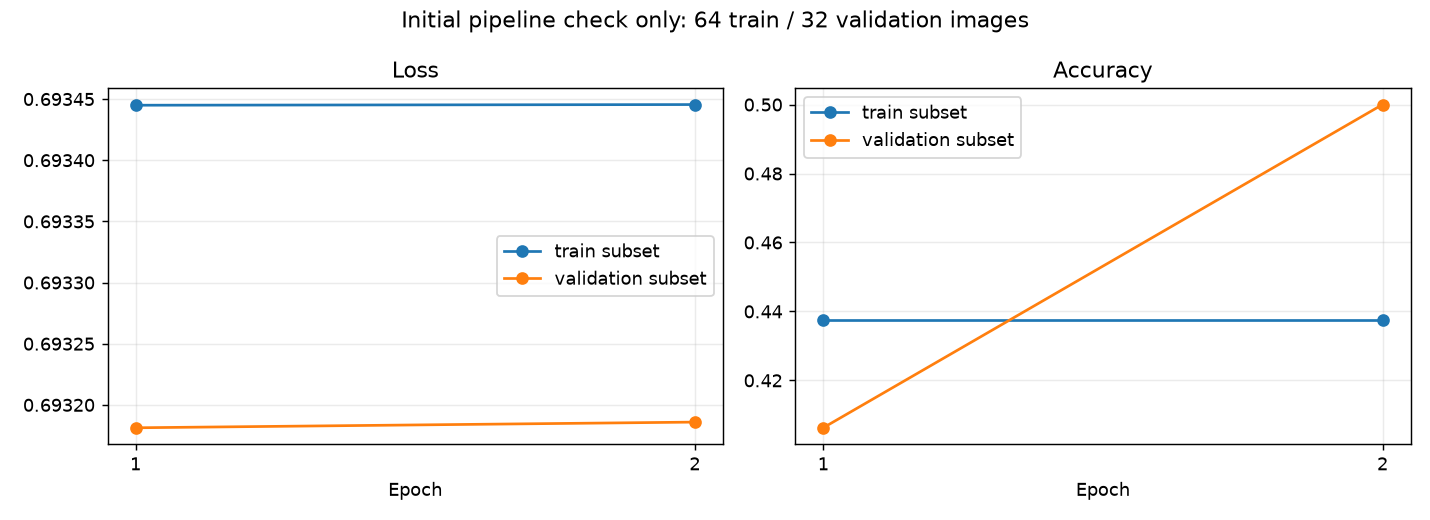

In [6]:
results = json.loads((ROOT / 'reports' / 'initial_training_results.json').read_text())
print('Completed epochs:', results['epochs_completed'])
print('Training/validation images used:', results['training_images_used'], results['validation_images_used'])
print('Checkpoint:', results['checkpoint'])
print('Checkpoint reload passed:', results['checkpoint_reload_passed'])
print('Training history:', json.dumps(results['history'], indent=2))
print('Test set evaluated:', results['test_set_evaluated'])
assert results['checkpoint_reload_passed'] and not results['test_set_evaluated']
display(DisplayImage(filename=str(ROOT / 'reports' / 'figures' / 'initial_training_history.png')))


## Next stages

Continue with full training and a documented validation-driven optimization study. Reserve the test set for the final evaluation, confusion matrix, and example predictions. This initial run does not establish useful classification performance.
